In [53]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import BaggingClassifier , AdaBoostClassifier , AdaBoostRegressor , BaggingRegressor
from sklearn.tree import DecisionTreeRegressor , DecisionTreeClassifier
from sklearn.metrics import accuracy_score ,r2_score, mean_squared_error
import matplotlib.pyplot as plt

In [54]:
df=pd.read_csv("data.csv")
df.head()

,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4


- 6.Identify features and target variables for both tasks.

In [55]:
df.drop(['student_id','course_start_date'], axis=1, inplace=True)
feature_columns = df.columns[:-2]
target_columns = df.columns[-2:]
print("Feature Columns:", feature_columns)
print("Target Columns:", target_columns)

Feature Columns: Index(['age', 'country_region', 'device_type', 'education_background',
       'course_level', 'course_category', 'week_of_year', 'sessions',
       'time_spent_hours', 'videos_watched', 'quiz_attempts',
       'assignments_submitted', 'forum_posts', 'avg_quiz_score',
       'attendance_rate'],
      dtype='object')
Target Columns: Index(['completion_status', 'final_score'], dtype='object')


- 8.Apply basic preprocessing

In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    5200 non-null   int64  
 1   country_region         5200 non-null   object 
 2   device_type            5200 non-null   object 
 3   education_background   5200 non-null   object 
 4   course_level           5200 non-null   object 
 5   course_category        5200 non-null   object 
 6   week_of_year           5200 non-null   int64  
 7   sessions               5200 non-null   int64  
 8   time_spent_hours       5088 non-null   float64
 9   videos_watched         5200 non-null   int64  
 10  quiz_attempts          5200 non-null   int64  
 11  assignments_submitted  5200 non-null   int64  
 12  forum_posts            5200 non-null   int64  
 13  avg_quiz_score         5119 non-null   float64
 14  attendance_rate        5120 non-null   float64
 15  comp

In [57]:
# Missing Values Handle
cols_with_null = ['time_spent_hours', 'avg_quiz_score', 'attendance_rate']
for col in cols_with_null:
    df[col] = df[col].fillna(df[col].median())

# Categorical Encoding
cat_cols = ['country_region', 'device_type', 'education_background', 'course_level', 'course_category']
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))

# 4. Feature Scaling (StandardScaler)
num_cols = ['age', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 
            'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate']
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

print("Null values remaining:", df.isnull().sum().sum())
print("\nPreprocessed Data Preview:")
df.head()
    

Null values remaining: 0

Preprocessed Data Preview:


,age,country_region,device_type,education_background,course_level,course_category,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,1.373240,3,0,2,2,0,-0.974361,-1.689583,-0.995226,-1.402629,-0.387795,-1.453038,-0.460896,-0.988243,-1.706965,0,49.8
1,-1.315738,3,0,2,2,4,0.491691,-0.291070,0.850125,-1.120443,-1.166681,1.621340,-0.460896,-1.119585,1.355309,1,84.0
2,0.118384,3,1,0,0,4,0.824885,-1.223412,-1.042301,-0.556070,-1.945567,-0.940642,-1.247977,-0.338828,-0.331161,0,62.5
3,0.297649,2,1,2,1,2,-1.107638,1.387146,0.369957,1.757858,0.780534,1.108944,-1.247977,-0.550435,0.245789,1,89.5
4,0.297649,2,2,3,0,0,-0.974361,0.268335,1.330293,0.854862,0.780534,-0.940642,-1.247977,-0.127221,-0.295656,0,67.4


- 7.Perform a train–test split for classification and regression problems.

In [58]:
x=df[feature_columns]
y=df[target_columns]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

### 📦 Part C: Bagging (Bootstrap Aggregating)

- 9.Implement Bagging Classifier for course completion prediction.

In [59]:
# Bagging Classifier
bag_clf = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=50, random_state=42)
bag_clf.fit(x_train, y_train['completion_status'])

# Prediction & Evaluation
y_pred_bag_clf = bag_clf.predict(x_test)
print("Bagging Classifier Accuracy:", accuracy_score(y_test['completion_status'], y_pred_bag_clf))

Bagging Classifier Accuracy: 0.6961538461538461


- 10.Implement Bagging Regressor for final score prediction.

In [60]:
# Bagging Regressor
bag_reg = BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=50, random_state=42)
bag_reg.fit(x_train, y_train['final_score'])
# Prediction & Evaluation
y_pred_bag_reg = bag_reg.predict(x_test)
print("Bagging Regressor R2 Score:", r2_score(y_test['final_score'], y_pred_bag_reg))

Bagging Regressor R2 Score: 0.45077448052522473


- 11.Compare bagging results with a single base model.Compare bagging results with a single base model.

In [61]:
# Single Decision Tree Models
base_tree_clf = DecisionTreeClassifier(random_state=42)
base_tree_clf.fit(x_train, y_train['completion_status'])
tree_clf_acc = accuracy_score(y_test['completion_status'], base_tree_clf.predict(x_test))

base_tree_reg = DecisionTreeRegressor(random_state=42)
base_tree_reg.fit(x_train, y_train['final_score'])
tree_reg_r2 = r2_score(y_test['final_score'], base_tree_reg.predict(x_test))

# Comparison Output
print("--- Classification Comparison ---")
print("Single Decision Tree Accuracy :", tree_clf_acc)
print("Bagging Classifier Accuracy   :", accuracy_score(y_test['completion_status'], y_pred_bag_clf))

print("\n--- Regression Comparison ---")
print("Single Decision Tree R2 Score :", tree_reg_r2)
print("Bagging Regressor R2 Score    :", r2_score(y_test['final_score'], y_pred_bag_reg))

--- Classification Comparison ---
Single Decision Tree Accuracy : 0.6125
Bagging Classifier Accuracy   : 0.6961538461538461

--- Regression Comparison ---
Single Decision Tree R2 Score : -0.015834151966168886
Bagging Regressor R2 Score    : 0.45077448052522473


### ⚡ Part D: Boosting Algorithms

#### AdaBoost
- 12.Implement AdaBoost Classifier.

In [62]:
# AdaBoost Classifier
ada_clf = AdaBoostClassifier(n_estimators=50, random_state=42)
ada_clf.fit(x_train, y_train['completion_status'])
# Prediction & Evaluation
y_pred_ada_clf = ada_clf.predict(x_test)
print("AdaBoost Classifier Accuracy:", accuracy_score(y_test['completion_status'], y_pred_ada_clf))

AdaBoost Classifier Accuracy: 0.7182692307692308


- 13.Implement AdaBoost Regressor.

In [63]:
# AdaBoost Regressor
ada_reg = AdaBoostRegressor(n_estimators=50, random_state=42)
ada_reg.fit(x_train, y_train['final_score'])
# Prediction & Evaluation
y_pred_ada_reg = ada_reg.predict(x_test)
print("AdaBoost Regressor R2 Score:", r2_score(y_test['final_score'], y_pred_ada_reg))

AdaBoost Regressor R2 Score: 0.397084879310197


- 14.Analyze how weak learners improve sequentially.

C:\Users\ansh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
C:\Users\ansh\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(


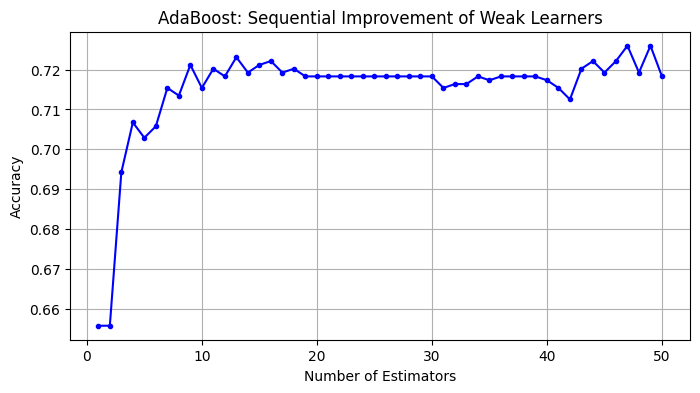

Initial (1st tree) Accuracy : 0.6557692307692308
Final (50th tree) Accuracy  : 0.7182692307692308


In [64]:
import matplotlib.pyplot as plt

staged_acc = list(ada_clf.staged_score(x_test, y_test['completion_status']))

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(staged_acc) + 1), staged_acc, color='blue', marker='o', markersize=3)
plt.title("AdaBoost: Sequential Improvement of Weak Learners")
plt.xlabel("Number of Estimators")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

print("Initial (1st tree) Accuracy :", staged_acc[0])
print("Final (50th tree) Accuracy  :", staged_acc[-1])

#### Gradient Boosting
- 15.Implement Gradient Boosting Classifier.

In [65]:
from sklearn.ensemble import GradientBoostingClassifier

# 15. Gradient Boosting Classifier
gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb_clf.fit(x_train, y_train['completion_status'])

y_pred_gb_clf = gb_clf.predict(x_test)
print('Gradient Boosting Classifier Accuracy:', accuracy_score(y_test['completion_status'], y_pred_gb_clf))

Gradient Boosting Classifier Accuracy: 0.7192307692307692


- 16.Implement Gradient Boosting Regressor.

In [66]:
from sklearn.ensemble import GradientBoostingRegressor

# 16. Gradient Boosting Regressor
gb_reg = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
gb_reg.fit(x_train, y_train['final_score'])

y_pred_gb_reg = gb_reg.predict(x_test)
print('Gradient Boosting Regressor R2 Score:', r2_score(y_test['final_score'], y_pred_gb_reg))

Gradient Boosting Regressor R2 Score: 0.48614716049847995


- 17.Analyze learning rate and number of estimators.

In [67]:
# 17. Analyze learning rate and number of estimators
learning_rates = [0.01, 0.05, 0.1, 0.2]
n_estimators_list = [50, 100, 150]

for lr in learning_rates:
    for n_est in n_estimators_list:
        model = GradientBoostingClassifier(n_estimators=n_est, learning_rate=lr, random_state=42)
        model.fit(x_train, y_train['completion_status'])
        acc = accuracy_score(y_test['completion_status'], model.predict(x_test))
        print(f'Learning Rate: {lr}, Estimators: {n_est} -> Accuracy: {acc:.4f}')

Learning Rate: 0.01, Estimators: 50 -> Accuracy: 0.6577
Learning Rate: 0.01, Estimators: 100 -> Accuracy: 0.7106
Learning Rate: 0.01, Estimators: 150 -> Accuracy: 0.7260
Learning Rate: 0.05, Estimators: 50 -> Accuracy: 0.7212
Learning Rate: 0.05, Estimators: 100 -> Accuracy: 0.7231
Learning Rate: 0.05, Estimators: 150 -> Accuracy: 0.7250
Learning Rate: 0.1, Estimators: 50 -> Accuracy: 0.7221
Learning Rate: 0.1, Estimators: 100 -> Accuracy: 0.7192
Learning Rate: 0.1, Estimators: 150 -> Accuracy: 0.7250
Learning Rate: 0.2, Estimators: 50 -> Accuracy: 0.7250
Learning Rate: 0.2, Estimators: 100 -> Accuracy: 0.7192
Learning Rate: 0.2, Estimators: 150 -> Accuracy: 0.7087


#### Light Gradient Boosting
- 18.Implement LightGBM Classifier.

In [68]:
from lightgbm import LGBMClassifier

# 18. LightGBM Classifier
lgb_clf = LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
lgb_clf.fit(x_train, y_train['completion_status'])

y_pred_lgb_clf = lgb_clf.predict(x_test)
print('LightGBM Classifier Accuracy:', accuracy_score(y_test['completion_status'], y_pred_lgb_clf))

LightGBM Classifier Accuracy: 0.7067307692307693


- 19.Implement LightGBM Regressor.

In [69]:
from lightgbm import LGBMRegressor

# 19. LightGBM Regressor
lgb_reg = LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
lgb_reg.fit(x_train, y_train['final_score'])

y_pred_lgb_reg = lgb_reg.predict(x_test)
print('LightGBM Regressor R2 Score:', r2_score(y_test['final_score'], y_pred_lgb_reg))

LightGBM Regressor R2 Score: 0.4613136648033408


- 20.Analyze performance and training efficiency.

In [70]:
import time

# 20. Compare Training Time & Performance: GradientBoosting vs LightGBM
t0 = time.time()
gb_clf.fit(x_train, y_train['completion_status'])
gb_time = time.time() - t0

t0 = time.time()
lgb_clf.fit(x_train, y_train['completion_status'])
lgb_time = time.time() - t0

print(f'Gradient Boosting Training Time : {gb_time:.4f} sec | Accuracy: {accuracy_score(y_test["completion_status"], y_pred_gb_clf):.4f}')
print(f'LightGBM Training Time          : {lgb_time:.4f} sec | Accuracy: {accuracy_score(y_test["completion_status"], y_pred_lgb_clf):.4f}')

Gradient Boosting Training Time : 1.1067 sec | Accuracy: 0.7192
LightGBM Training Time          : 0.0920 sec | Accuracy: 0.7067


#### XGBoost
- 21.Implement XGBoost Classifier.

In [71]:
from xgboost import XGBClassifier

# 21. XGBoost Classifier
xgb_clf = XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, eval_metric='logloss')
xgb_clf.fit(x_train, y_train['completion_status'])

y_pred_xgb_clf = xgb_clf.predict(x_test)
print('XGBoost Classifier Accuracy:', accuracy_score(y_test['completion_status'], y_pred_xgb_clf))

XGBoost Classifier Accuracy: 0.7115384615384616


- 22.Implement XGBoost Regressor.

In [72]:
from xgboost import XGBRegressor

# 22. XGBoost Regressor
xgb_reg = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_reg.fit(x_train, y_train['final_score'])

y_pred_xgb_reg = xgb_reg.predict(x_test)
print('XGBoost Regressor R2 Score:', r2_score(y_test['final_score'], y_pred_xgb_reg))

XGBoost Regressor R2 Score: 0.46793272257628804


- 23.Compare performance and robustness with other boosting models.

In [73]:
# 23. Compare Boosting Models Performance
print('--- Boosting Models Classification Comparison ---')
print('AdaBoost Accuracy          :', accuracy_score(y_test['completion_status'], y_pred_ada_clf))
print('Gradient Boosting Accuracy :', accuracy_score(y_test['completion_status'], y_pred_gb_clf))
print('LightGBM Accuracy          :', accuracy_score(y_test['completion_status'], y_pred_lgb_clf))
print('XGBoost Accuracy           :', accuracy_score(y_test['completion_status'], y_pred_xgb_clf))

print('\n--- Boosting Models Regression Comparison (R2 Score) ---')
print('AdaBoost R2 Score          :', r2_score(y_test['final_score'], y_pred_ada_reg))
print('Gradient Boosting R2 Score :', r2_score(y_test['final_score'], y_pred_gb_reg))
print('LightGBM R2 Score          :', r2_score(y_test['final_score'], y_pred_lgb_reg))
print('XGBoost R2 Score           :', r2_score(y_test['final_score'], y_pred_xgb_reg))

--- Boosting Models Classification Comparison ---
AdaBoost Accuracy          : 0.7182692307692308
Gradient Boosting Accuracy : 0.7192307692307692
LightGBM Accuracy          : 0.7067307692307693
XGBoost Accuracy           : 0.7115384615384616

--- Boosting Models Regression Comparison (R2 Score) ---
AdaBoost R2 Score          : 0.397084879310197
Gradient Boosting R2 Score : 0.48614716049847995
LightGBM R2 Score          : 0.4613136648033408
XGBoost R2 Score           : 0.46793272257628804


### 🗳️ Part E: Voting & Stacking Ensembles
- 24.Implement Voting Classifier using multiple base classifiers.

In [74]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Base classifiers
clf1 = LogisticRegression(max_iter=1000, random_state=42)
clf2 = RandomForestClassifier(n_estimators=50, random_state=42)
clf3 = GradientBoostingClassifier(n_estimators=50, random_state=42)

# 24. Hard Voting Classifier
voting_hard = VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('gb', clf3)], voting='hard')
voting_hard.fit(x_train, y_train['completion_status'])

y_pred_voting_hard = voting_hard.predict(x_test)
print('Voting Classifier (Hard) Accuracy:', accuracy_score(y_test['completion_status'], y_pred_voting_hard))

Voting Classifier (Hard) Accuracy: 0.7298076923076923


- 25.Compare Hard Voting vs Soft Voting.

In [75]:
# 25. Soft Voting Classifier & Comparison
voting_soft = VotingClassifier(estimators=[('lr', clf1), ('rf', clf2), ('gb', clf3)], voting='soft')
voting_soft.fit(x_train, y_train['completion_status'])

y_pred_voting_soft = voting_soft.predict(x_test)
print('Hard Voting Accuracy :', accuracy_score(y_test['completion_status'], y_pred_voting_hard))
print('Soft Voting Accuracy :', accuracy_score(y_test['completion_status'], y_pred_voting_soft))

Hard Voting Accuracy : 0.7298076923076923
Soft Voting Accuracy : 0.7201923076923077


- 26.Implement Stacking Classifier with a meta-learner.

In [76]:
from sklearn.ensemble import StackingClassifier

# 26. Stacking Classifier with Meta-Learner (LogisticRegression)
stack_clf = StackingClassifier(
    estimators=[('rf', RandomForestClassifier(n_estimators=50, random_state=42)),
                ('gb', GradientBoostingClassifier(n_estimators=50, random_state=42))],
    final_estimator=LogisticRegression()
)
stack_clf.fit(x_train, y_train['completion_status'])

y_pred_stack_clf = stack_clf.predict(x_test)
print('Stacking Classifier Accuracy:', accuracy_score(y_test['completion_status'], y_pred_stack_clf))

Stacking Classifier Accuracy: 0.7269230769230769


- 27.Implement Stacking Regressor for score prediction.

In [77]:
from sklearn.ensemble import StackingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge

# 27. Stacking Regressor for final score prediction
stack_reg = StackingRegressor(
    estimators=[('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
                ('gb', GradientBoostingRegressor(n_estimators=50, random_state=42))],
    final_estimator=Ridge()
)
stack_reg.fit(x_train, y_train['final_score'])

y_pred_stack_reg = stack_reg.predict(x_test)
print('Stacking Regressor R2 Score:', r2_score(y_test['final_score'], y_pred_stack_reg))

Stacking Regressor R2 Score: 0.4812740011979829


### 📊 Part F: Model Evaluation & Comparison
- 28.Evaluate classification models using:
  - Accuracy
  - Precision, Recall, F1-Score
  - ROC-AUC

In [78]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# 28. Evaluate All Classification Models
models_clf = {
    'Bagging': bag_clf,
    'AdaBoost': ada_clf,
    'GradientBoosting': gb_clf,
    'LightGBM': lgb_clf,
    'XGBoost': xgb_clf,
    'Voting (Soft)': voting_soft,
    'Stacking': stack_clf
}

clf_summary = []
for name, model in models_clf.items():
    preds = model.predict(x_test)
    probs = model.predict_proba(x_test)[:, 1] if hasattr(model, 'predict_proba') else preds
    clf_summary.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test['completion_status'], preds),
        'Precision': precision_score(y_test['completion_status'], preds),
        'Recall': recall_score(y_test['completion_status'], preds),
        'F1-Score': f1_score(y_test['completion_status'], preds),
        'ROC-AUC': roc_auc_score(y_test['completion_status'], probs)
    })

df_clf_eval = pd.DataFrame(clf_summary)
df_clf_eval

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Bagging,0.696154,0.619938,0.506361,0.557423,0.735959
1,AdaBoost,0.718269,0.650602,0.549618,0.595862,0.769022
2,GradientBoosting,0.719231,0.652568,0.549618,0.596685,0.769447
3,LightGBM,0.706731,0.628655,0.547074,0.585034,0.761967
4,XGBoost,0.711538,0.636364,0.552163,0.591281,0.753094
5,Voting (Soft),0.720192,0.663462,0.526718,0.587234,0.770941
6,Stacking,0.726923,0.671924,0.541985,0.600000,0.769352


- 29.Evaluate regression models using:
  - MAE, RMSE
  - R² Score

In [79]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 29. Evaluate All Regression Models
models_reg = {
    'Bagging': bag_reg,
    'AdaBoost': ada_reg,
    'GradientBoosting': gb_reg,
    'LightGBM': lgb_reg,
    'XGBoost': xgb_reg,
    'Stacking': stack_reg
}

reg_summary = []
for name, model in models_reg.items():
    preds = model.predict(x_test)
    mae = mean_absolute_error(y_test['final_score'], preds)
    rmse = np.sqrt(mean_squared_error(y_test['final_score'], preds))
    r2 = r2_score(y_test['final_score'], preds)
    reg_summary.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

df_reg_eval = pd.DataFrame(reg_summary)
df_reg_eval

,Model,MAE,RMSE,R2 Score
0,Bagging,8.105215,10.130008,0.450774
1,AdaBoost,8.661746,10.613595,0.397085
2,GradientBoosting,7.873275,9.798369,0.486147
3,LightGBM,8.034059,10.032344,0.461314
4,XGBoost,8.015074,9.970517,0.467933
5,Stacking,7.862626,9.844721,0.481274


- 30.Compare all ensemble techniques and identify the best performing model for each task.

In [80]:
# 30. Best Performing Models
best_clf = df_clf_eval.sort_values(by='F1-Score', ascending=False).iloc[0]
print(f"🏆 Best Classification Model: {best_clf['Model']} (Accuracy: {best_clf['Accuracy']:.4f}, F1-Score: {best_clf['F1-Score']:.4f})")

best_reg = df_reg_eval.sort_values(by='R2 Score', ascending=False).iloc[0]
print(f"🏆 Best Regression Model    : {best_reg['Model']} (R2 Score: {best_reg['R2 Score']:.4f}, RMSE: {best_reg['RMSE']:.4f})")

🏆 Best Classification Model: Stacking (Accuracy: 0.7269, F1-Score: 0.6000)
🏆 Best Regression Model    : GradientBoosting (R2 Score: 0.4861, RMSE: 9.7984)
